# Zero-shot CLIP for vehicle counts at an unlabelled camera (UVH-26)

AIML ZG525 Computer Vision, EC-1 Assignment 2 · Track C (vision-language, zero-shot classification)
Yash Renwa, 2025AG05357

A frozen CLIP ViT-B/16 names each ground-truth vehicle box in UVH-26 frames as one of the 14 dataset
classes. Per-frame counts become PCU (IRC:106-1990), and a confidence threshold decides which crops a
person checks. Nothing is trained.

- Runs top to bottom on a fresh kernel, on CPU (local) or a free Colab runtime.
- **`EVALUATE_TEST`** (next cell): `True` scores the sealed test split. The prompts (`prompts/ensemble.yaml`)
  and the review threshold (`results/frozen_rule.json`) were fixed on val before test was first opened
  (2026-11-10); this run re-scores test with exactly those files and changes nothing.
- Images are downloaded from the Hugging Face Hub at a pinned revision. Locally, `UVH_RAW_ROOT` can point
  to the PNGs already downloaded for Assignment 1.
- Image embeddings stay in memory: this run writes none to disk (checked in step 8).
- Sections follow the brief's eight steps. Every number in the report is printed in a cell output and
  collected into `report/numbers.json` at the end.

In [1]:
# ---- Run settings ----
EVALUATE_TEST = True   # opens the sealed test split with the frozen prompts and threshold
REPO_URL = "https://github.com/YashRenwa/uvh26-clip-zeroshot.git"
COMMIT = "3c8a2010f30f6b2fd5e0aa24af32cb195118968b"  # code pinned for the submitted run ("main" follows the latest)
A1_RAW = "../uvh26-pcu-counting/data/raw"   # local only, relative to the repo: Assignment 1's PNGs (skips the download)

In [2]:
import os, subprocess, sys, time
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
RUN_STARTED = time.time()
os.environ.setdefault("TQDM_MININTERVAL", "60")   # sparse progress bars keep the saved notebook small


def sh(cmd):
    print("$", cmd)
    subprocess.run(cmd, shell=True, check=True)


if IN_COLAB:
    repo_dir = Path("/content/uvh26-clip-zeroshot")
    if not repo_dir.exists():
        sh(f"git clone -q {REPO_URL} {repo_dir}")
    os.chdir(repo_dir)
    sh("git fetch -q origin")
    is_branch = subprocess.run(f"git rev-parse -q --verify origin/{COMMIT}", shell=True, capture_output=True).returncode == 0
    sh(f"git checkout -q -f --detach {'origin/' + COMMIT if is_branch else COMMIT}")
    # keep Colab's preinstalled torch/numpy/opencv builds; pin the rest
    sh("grep -v colab-skip requirements.txt > /tmp/req-colab.txt && pip install -q -r /tmp/req-colab.txt")
    os.environ["UVH_RAW_ROOT"] = "/content/raw"     # PNGs are fetched from the Hub into here
else:
    if Path.cwd().name == "notebooks":
        os.chdir("..")
    if Path(A1_RAW).is_dir():
        os.environ.setdefault("UVH_RAW_ROOT", str(Path(A1_RAW).resolve()))
sys.path.insert(0, str(Path.cwd()))
if EVALUATE_TEST:
    os.environ["EVALUATE_TEST"] = "1"
print("working directory:", Path.cwd(), "| raw images:", os.environ.get("UVH_RAW_ROOT", "data/raw (Hub download)"))

working directory: /Users/yashrenwa/Personal/Projects/uvh26-clip-zeroshot | raw images: /Users/yashrenwa/Personal/Projects/uvh26-pcu-counting/data/raw


In [3]:
import io, json
import numpy as np
import pandas as pd
import torch
from IPython.display import Image as ShowImage, display
from PIL import Image

from src.common import ROOT, load_config, run_header, set_seed

SMOKE = os.environ.get("UVH_SMOKE") == "1"   # quick local check on 20 val images; outputs go to data/smoke/
cfg = load_config(smoke=SMOKE)
set_seed(cfg["seed"])
torch.set_num_threads(max(1, os.cpu_count() or 1))
header = run_header(cfg)
for k, v in header.items():
    if k != "versions":
        print(f"{k:17s} {v}")
for name, version in header["versions"].items():
    print(f"  {name:16s} {version}")
RES = cfg["paths"]["results_dir"]
pd.set_option("display.width", 160, "display.max_columns", 30)


def show(path, width=900):
    """Display a saved figure downscaled (keeps the notebook small)."""
    im = Image.open(ROOT / path).convert("RGB")
    if im.width > width:
        im = im.resize((width, round(im.height * width / im.width)), Image.LANCZOS)
    buf = io.BytesIO()
    im.save(buf, "JPEG", quality=82)
    display(ShowImage(buf.getvalue()))


def recorded(name):
    return json.loads((ROOT / "results" / f"{name}.json").read_text())

seed              42
model             openai/clip-vit-base-patch16
model_revision    57c216476eefef5ab752ec549e440a49ae4ae5f3
dataset           iisc-aim/UVH-26
dataset_revision  59f82c57821e8a54dc40bc1f42e83909dbad0b70
device            cpu
  python           3.12.13
  numpy            2.5.3
  matplotlib       3.11.2
  torch            2.14.1
  torchvision      0.29.1
  opencv-python    4.14.0.94
  transformers     5.18.0
  huggingface-hub  1.33.0
  pandas           3.0.6
  pyyaml           6.0.3
  tqdm             4.70.1
  pillow           13.0.0


## 1. Problem and track

**Decision supported.** Signal green time at a junction is planned from traffic demand in PCU (passenger
car units), which needs per-frame counts by vehicle class. At a new camera there are no labels. Can a
model nobody trained on these cameras turn boxed vehicles into class counts good enough for PCU, and can
its own score say which crops a person must check?

**Why Track C.** A zero-shot vision-language model is the only option that gives class names at a camera
with zero labelled images: the classes are described in words, not learned. Track A (ViT vs CNN) needs a
labelled training set for both models, which is the thing an unlabelled camera lacks. Track B (generation)
produces images, not counts; synthetic traffic would not tell a planner anything about this junction.

**Scope.** Boxes are the dataset's ground-truth boxes (UVH-26-ST), so this measures classification only.
Assignment 1's fine-tuned YOLOv8 on the same split is quoted once, as what labelled training bought; its
numbers include detection errors, ours do not.

## 2. Data, licence and contamination

- **Source.** `iisc-aim/UVH-26` on the Hugging Face Hub (CC BY 4.0), pinned revision below. 1920×1080
  frames from Bengaluru traffic cameras, captured February 2025, with 14 vehicle classes.
- **Split.** Assignment 1's pseudo-camera split, reused unchanged and checksum-verified: val 452 images,
  test 477 images, no pseudo-camera group in both. Exact duplicate ST boxes are dropped (same rule as
  Assignment 1).
- **Crops.** Each box becomes a square crop with 10% context, padded with CLIP's mean pixel. Crops are
  generated in memory; only a manifest (box, size, overlap and frame-edge tags) is kept.

The cell below rebuilds both crop manifests from the raw annotations and checks they equal the
committed ones, so every later number refers to the same crops.

In [4]:
from src.common import read_split, verify_test_split
from src.crops import build_manifest

print("splits/test.txt sha256:", verify_test_split(cfg))
splits = {"val": read_split(cfg, "val"), "test": read_split(cfg, "test")}
if SMOKE:
    splits = {"val": splits["val"][: cfg["smoke_images"]]}
manifests = {}
for split, stems in splits.items():
    m, summary = build_manifest(cfg, split, stems)
    committed = pd.read_csv(ROOT / "results" / f"crops_{split}.csv", dtype={"stem": str, "group": str})
    committed = committed[committed["stem"].isin(stems)]
    assert m.to_csv(index=False) == committed.to_csv(index=False), f"{split} manifest differs from the committed one"
    manifests[split] = committed.reset_index(drop=True)
    print(f"{split}: {summary['images']} images, {summary['raw_boxes']} raw boxes, "
          f"{summary['exact_duplicates_dropped']} exact duplicates dropped -> {len(m)} crops "
          f"({m['group'].nunique()} pseudo-cameras); matches the committed manifest")
pd.read_csv(ROOT / "results" / "split_class_counts.csv", index_col=0).T

splits/test.txt sha256: f8181d247d7e034f5810b2bb2a978e2739e5055dbc8b3240877c5caa1f667ff6


val frames:   0%|          | 0/452 [00:00<?, ?it/s]

val frames: 100%|██████████| 452/452 [00:02<00:00, 189.96it/s]

val: 452 images, 6681 raw boxes, 51 exact duplicates dropped -> 6630 crops (355 pseudo-cameras); matches the committed manifest


test frames:   0%|          | 0/477 [00:00<?, ?it/s]

test frames: 100%|██████████| 477/477 [00:02<00:00, 187.15it/s]

test: 477 images, 6350 raw boxes, 51 exact duplicates dropped -> 6299 crops (410 pseudo-cameras); matches the committed manifest


class,Hatchback,Sedan,SUV,MUV,Bus,Truck,Three-wheeler,Two-wheeler,LCV,Mini-bus,Tempo-traveller,Bicycle,Van,Others,total
val,619,379,347,223,212,350,1006,2981,329,18,21,97,44,4,6630
test,607,356,300,212,147,339,937,2816,372,25,28,95,62,3,6299


In [5]:
prov = recorded("provenance")
leak = prov["test_val_leakage"]
print("pinned revisions:", json.dumps(prov["hub"], indent=1))
print("split:", prov["split"])
lo, hi = leak["leakage_95ci"]
print(f"test-vs-val same-camera audit: {leak['same_camera']} of {leak['n']} seeded test images have a same-camera "
      f"val image -> about {leak['leakage_estimate']:.0%} (95% CI {lo:.0%}-{hi:.0%})\n  method: {leak['method']}\n  {leak['finding']}")
pd.Series(prov["contamination"]).to_frame("contamination notes")

pinned revisions: {
 "model_sha": "57c216476eefef5ab752ec549e440a49ae4ae5f3",
 "model_last_modified": "2022-10-04 09:42:28+00:00",
 "dataset_sha": "59f82c57821e8a54dc40bc1f42e83909dbad0b70",
 "dataset_last_modified": "2025-12-10 09:33:48+00:00",
 "dataset_license_tag": "cc-by-4.0"
}
split: {'val_images': 452, 'val_groups': 355, 'test_images': 477, 'test_groups': 410, 'groups_shared_val_test': 0, 'images_shared_val_test': 0}
test-vs-val same-camera audit: 4 of 40 seeded test images have a same-camera val image -> about 10% (95% CI 4%-23%)
  method: 40 random test images (numpy default_rng(seed=42).permutation), each paired with its most similar val image by 64x36 gradient-magnitude correlation g (A1 protocol); judged by eye: same / unclear / different
  Pairs #12 and #13 are the same camera at g ~ 0.25 because a large vehicle fills the frame and hides the static scene edges. So the g-based count (18 test images with a val neighbour at g >= 0.36, none at >= 0.48) is not an upper bound on

,contamination notes
uvh26,{'title': 'The Urban Vision Hackathon Dataset ...
clip,"{'model': 'openai/clip-vit-base-patch16', 'tit..."
conclusion,"UVH-26 frames were captured in February 2025, ..."
caveat,"The concepts (auto-rickshaws, Indian buses, CC..."
own_leakage,Prompts and the review threshold are chosen on...
a1_clip_use,Assignment 1 used CLIP ViT-B/32 embeddings onl...


**What CLIP has probably seen.** CLIP ViT-B/16 was trained on 400M web image-text pairs collected before
January 2021; the UVH-26 frames were captured in February 2025 and published in 2025, so these exact
frames cannot be in its training data. Generic Indian street photos with captions such as "auto-rickshaw"
very likely are, which is what zero-shot relies on. Within the project, the prompt wording and the
threshold were chosen on val only; about 10% of test images share a camera with a val image (by-eye
audit above), and the prompts were written from the dataset's class definitions and revised at most
twice, so the effect of that overlap on the test numbers is small.

Example crops per class (val), one seeded random crop each, faces blurred. The Bicycle example is a car
carrying a duplicate STAPLE box labelled Bicycle; see the label-noise finding in Step 7.

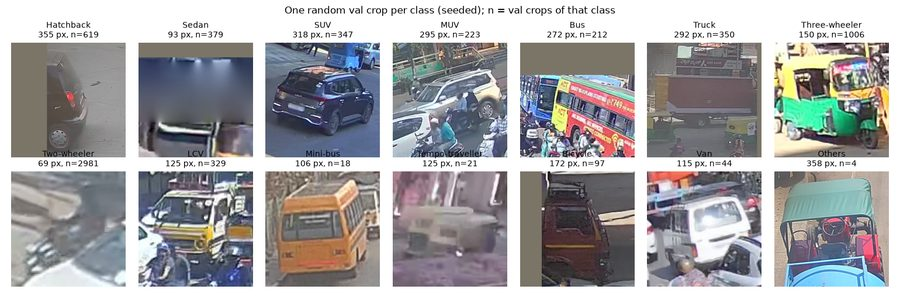

In [6]:
show("results/figures/val_examples.png")

## 3. The frozen baseline

`openai/clip-vit-base-patch16` at a pinned revision, used the way it was published: CLIP's own image
processor (224×224, its normalisation), L2-normalised image and text embeddings, logits = CLIP's learned
logit scale × cosine similarity, softmax over the 14 class prompts, prediction = argmax. Nothing is
fine-tuned, no temperature is fitted, no weights change. The baseline prompt is the standard
`"a photo of a {class name}."`.

For PCU, classes map to IRC:106-1990 categories. The IRC category is the one with the highest **summed**
softmax score over its classes (fixed on val before test was opened); the 14-class metrics use the plain
argmax. The argmax→category version is printed alongside as a secondary column.

In [7]:
from src.zeroshot import load_model, logit_scale

model, processor = load_model(cfg)
n_params = sum(p.numel() for p in model.parameters())
print(f"{cfg['model']['id']} @ {cfg['model']['revision']} | {n_params / 1e6:.1f}M parameters, all frozen "
      f"| logit scale {logit_scale(model):.1f} | device {cfg['model']['device']}")
print("baseline prompts:", Path("prompts/baseline.yaml").read_text())

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

openai/clip-vit-base-patch16 @ 57c216476eefef5ab752ec549e440a49ae4ae5f3 | 149.6M parameters, all frozen | logit scale 100.0 | device cpu
baseline prompts: # Baseline text prompts: CLIP's own zero-shot recipe with the dataset's class names.
# One template x one name per class. Written and frozen before any val crop is scored (Phase 2).
# Names are the class names lowercased, hyphens kept; acronyms stay upper case; "Others" becomes
# "other vehicle" for grammar only. The template's article is kept as "a" for every class.
arm: baseline
templates:
  - "a photo of a {}."
names:
  Hatchback: [hatchback]
  Sedan: [sedan]
  SUV: [SUV]
  MUV: [MUV]
  Bus: [bus]
  Truck: [truck]
  Three-wheeler: [three-wheeler]
  Two-wheeler: [two-wheeler]
  LCV: [LCV]
  Mini-bus: [mini-bus]
  Tempo-traveller: [tempo-traveller]
  Bicycle: [bicycle]
  Van: [van]
  Others: [other vehicle]



## 4. One controlled intervention: the text prompts

The only change between the two arms is the text side. The **ensemble** arm averages, per class, the
text embeddings of six camera-aware templates × several descriptive names written from the dataset's
class definitions (`prompts/ensemble.yaml`, every name cites its row in the dataset card). The image
embeddings are computed **once** below and shared by both arms; the code asserts this.

Prompt design used val only. The baseline's val confusion was already known when the first version was
written; at most two revisions were allowed and the version with the best val IRC accuracy was frozen
(the log below). Both prompt files are registered by sha256 in `results/prompts_frozen.json`; the
classifier refuses any other file.

In [8]:
pd.read_csv(ROOT / "results" / "prompt_log.csv")

,version,file,sha256,n,accuracy,balanced_accuracy,macro_f1_headline,irc_accuracy,pcu_mae,pcu_bias,share_pred_others,recall_Three-wheeler,recall_LCV,recall_Others,recall_Hatchback,disclosure,reason
0,baseline,prompts/baseline.yaml,2e69fdead32879056fbb4607b06c8215f537a0ebaf0dfe...,6630,0.4730,0.2217,0.2485,0.5857,8.4285,8.1081,0.2095,0.1402,0.0061,0.00,0.0097,NaN,frozen baseline (reference row)
1,v1,prompts/ensemble_v1.yaml,c660a6c5ab95f346ab399c6413028bd8e1e7364ce6e26a...,6630,0.6066,0.3324,0.3751,0.7305,2.6066,0.8752,0.0686,0.5666,0.5775,0.25,0.3263,baseline val confusion known when v1 was written,written from card class table rows 1-14; CLIP-...
2,v2,prompts/ensemble_v2.yaml,84219edffad0223da81fd2bcb79708f01584fa5ccf1758...,6630,0.6276,0.3360,0.3876,0.7490,2.2729,0.6552,0.0425,0.7197,0.4195,0.25,0.3231,baseline val confusion known when v1 was written,v1 val confusion: Truck->LCV via 'mini truck' ...
3,v3,prompts/ensemble_v3.yaml,c680b2be0d0f38b3a385254e3013689020ef6da0e125ca...,6630,0.6294,0.3412,0.3922,0.7481,2.2747,0.5785,0.0430,0.7197,0.4316,0.25,0.3231,baseline val confusion known when v1 was written,v2 val confusion: truck_bus leaks to lcv/auto/...


In [9]:
from src.run_val import print_summary, run_arm
from src.zeroshot import embedding_fingerprint, image_embeddings

val = manifests["val"]
val_emb, val_timing = image_embeddings(cfg, model, processor, val, cache=None)   # in memory only
val_sha = embedding_fingerprint(val_emb)
if not SMOKE:
    assert val_sha == recorded("val_baseline")["image_embeddings_sha256"], "val image embeddings differ from the recorded run"
val_out, val_sm = {}, {}
for arm in ("baseline", "ensemble"):
    val_out[arm], val_sm[arm] = run_arm(cfg, model, processor, val, val_emb, val_timing, ROOT / "prompts" / f"{arm}.yaml")
    assert val_out[arm]["image_embeddings_sha256"] == val_sha   # one set of image embeddings for both arms
    print_summary(cfg, val_out[arm])
    print()

image embeddings:   0%|          | 0/6630 [00:00<?, ?it/s]

image embeddings:  31%|███       | 2048/6630 [01:01<02:16, 33.54it/s]

image embeddings:  31%|███       | 2048/6630 [01:17<02:16, 33.54it/s]

image embeddings:  62%|██████▏   | 4096/6630 [02:01<01:15, 33.68it/s]

image embeddings:  62%|██████▏   | 4096/6630 [02:17<01:15, 33.68it/s]

image embeddings:  94%|█████████▎| 6208/6630 [03:03<00:12, 33.97it/s]

image embeddings: 100%|██████████| 6630/6630 [03:14<00:00, 34.12it/s]

baseline on val (6630 crops): accuracy 0.473, balanced 0.222, macro-F1 0.249 (all present 0.198), IRC accuracy 0.586, PCU MAE 4.81 (26.0% of mean 18.48), bias +4.19 | secondary (argmax class): IRC accuracy 0.533, PCU MAE 8.43, bias +8.11
timing: {'crops': 6630, 'seconds': 195.4, 'ms_per_crop': 29.47, 'includes': 'PNG decode + crop + preprocessing + forward pass', 'device': 'cpu', 'batch_size': 64, 'peak_rss_mb': 1901.6, 'torch_threads': 12}
confusion (rows true, cols predicted):
                 Hatchb  Sedan  SUV  MUV  Bus  Truck  Three-  Two-wh  LCV  Mini-b  Tempo-  Bicycl  Van  Others
Hatchback             6     20  155    0    2      5       3     105    0       0       1       0   10     312
Sedan                 0     20   64    0    2      1       1      66    0       0       0       0    1     224
SUV                   1      1  148    0    3      5       1      45    1       1       1       0    2     138
MUV                   0      2   59    2    4      4       1      47    

ensemble on val (6630 crops): accuracy 0.628, balanced 0.336, macro-F1 0.388 (all present 0.312), IRC accuracy 0.749, PCU MAE 2.08 (11.2% of mean 18.48), bias +0.29 | secondary (argmax class): IRC accuracy 0.745, PCU MAE 2.27, bias +0.66
timing: {'crops': 6630, 'seconds': 195.4, 'ms_per_crop': 29.47, 'includes': 'PNG decode + crop + preprocessing + forward pass', 'device': 'cpu', 'batch_size': 64, 'peak_rss_mb': 1901.6, 'torch_threads': 12}
confusion (rows true, cols predicted):
                 Hatchb  Sedan  SUV  MUV  Bus  Truck  Three-  Two-wh  LCV  Mini-b  Tempo-  Bicycl  Van  Others
Hatchback           200     90  110   24    0      5      38      87   19       1       1       3   34       7
Sedan               111     96   44   18    0      0      25      61    4       0       0       2   18       0
SUV                  48     50  132   18    0      2      22      42   15       1       1       0   12       4
MUV                  28     24   39   16    0      1      25      33   1

## 5. Evaluation on data never tuned on

The review rule is fixed on val first: the lowest IRC score threshold *t* at which the crops accepted
without review reach 95% IRC accuracy (90% and 98% shown only for context). The cell checks that this
reproduces the frozen threshold exactly, then opens test.

Test is scored once per run with the frozen prompt files and threshold; the guard refuses to run unless
`EVALUATE_TEST` is set, `splits/test.txt` matches its checksum, and both prompt files and the rule match
their registered hashes. Confidence intervals are a paired percentile bootstrap over pseudo-camera groups
(1,000 resamples, seeded).

In [10]:
from src.confidence import run_confidence

conf = run_confidence(cfg, {arm: {"stems": val["stem"].to_numpy(), "true": val["cls"].to_numpy(), "softmax": val_sm[arm],
                                  "prompt_sha256": val_out[arm]["prompts"]["sha256"], "image_embeddings_sha256": val_sha}
                            for arm in ("baseline", "ensemble")})
frozen = recorded("frozen_rule")
for arm, r in conf["arms"].items():
    rule = r["rule"]
    if not SMOKE:
        assert rule["threshold"] == frozen["rules"][arm]["threshold"], "the val rule no longer reproduces the frozen threshold"
    ctx = ", ".join(f"{k}: coverage {v['coverage']:.1%}" for k, v in r["rule_context_only"].items())
    print(f"{arm}: t = {rule['threshold']:.4f} -> {rule['coverage']:.1%} of val crops accepted, accepted IRC accuracy "
          f"{rule['accepted_irc_accuracy']:.1%} | context only: {ctx}")
print("headline arm (chosen on val):", frozen["headline_arm"])

baseline: t = 0.8546 -> 11.5% of val crops accepted, accepted IRC accuracy 95.0% | context only: 0.90: coverage 30.8%, 0.98: coverage 0.5%
ensemble: t = 0.8956 -> 40.8% of val crops accepted, accepted IRC accuracy 95.0% | context only: 0.90: coverage 65.5%, 0.98: coverage 19.7%
headline arm (chosen on val): ensemble


In [11]:
from src.evaluate_test import evaluate

del val_emb   # val embeddings are no longer needed
first_test_sha = None if SMOKE else recorded("test_metrics")["image_embeddings_sha256"]
test = evaluate(cfg, note="notebook run (fresh kernel)", model=model, processor=processor)
if not SMOKE:
    assert test["image_embeddings_sha256"] == first_test_sha, "test image embeddings differ from the first opening"
    print("test image embeddings identical to the first test opening")
rows = {}
for arm, a in test["arms"].items():
    ci = test["bootstrap"]["per_arm_ci95"][arm] if "per_arm_ci95" in test["bootstrap"] else {}
    rows[arm] = {"accuracy": a["accuracy"], "balanced accuracy": a["balanced_accuracy"],
                 "macro-F1 (headline classes)": a["macro_f1_headline"], "IRC accuracy": a["irc_accuracy"],
                 "IRC accuracy (argmax, secondary)": a["irc_accuracy_from_class_argmax"],
                 "PCU MAE per frame": a["pcu"]["pcu_mae"], "PCU MAE / mean demand": a["pcu"]["pcu_rel_mae"],
                 "PCU bias": a["pcu"]["pcu_bias"], "ECE (IRC score)": a["irc_confidence"]["ece"]}
print(f"{test['split']}: {test['n_crops']} crops, {test['n_images']} images, {test['n_groups']} pseudo-cameras")
pd.DataFrame(rows).round(3)

image embeddings:   0%|          | 0/6299 [00:00<?, ?it/s]

image embeddings:  32%|███▏      | 2013/6299 [01:00<02:07, 33.54it/s]

image embeddings:  32%|███▏      | 2013/6299 [01:19<02:07, 33.54it/s]

image embeddings:  63%|██████▎   | 3968/6299 [02:00<01:10, 32.98it/s]

image embeddings:  63%|██████▎   | 3968/6299 [02:19<01:10, 32.98it/s]

image embeddings:  98%|█████████▊| 6144/6299 [03:00<00:04, 34.42it/s]

image embeddings: 100%|██████████| 6299/6299 [03:03<00:00, 34.27it/s]

test image embeddings identical to the first test opening
test: 6299 crops, 477 images, 410 pseudo-cameras


,baseline,ensemble
accuracy,0.455,0.626
balanced accuracy,0.205,0.378
macro-F1 (headline classes),0.230,0.396
IRC accuracy,0.575,0.742
"IRC accuracy (argmax, secondary)",0.514,0.739
PCU MAE per frame,4.768,1.976
PCU MAE / mean demand,0.289,0.120
PCU bias,4.099,0.724
ECE (IRC score),0.051,0.020


In [12]:
b = test["bootstrap"]
if "ensemble_minus_baseline" in b:
    print("ensemble minus baseline, 95% CI over pseudo-camera groups:")
    for k, d in b["ensemble_minus_baseline"].items():
        print(f"  {k:20s} [{d['ci95'][0]:+.3f}, {d['ci95'][1]:+.3f}]  (share of resamples above 0: {d['share_resamples_above_0']:.3f})")
    for arm, cis in b["per_arm_ci95"].items():
        print(f"{arm}: " + ", ".join(f"{k} [{lo:.3f}, {hi:.3f}]" for k, (lo, hi) in cis.items()))
pc = pd.DataFrame(test["arms"][frozen["headline_arm"]]["per_class"]).T[["precision", "recall", "f1", "support"]]
print(f"\nper class, {frozen['headline_arm']} arm on {test['split']} (low-support classes, excluded from the headline macro-F1:",
      ", ".join(test["low_support_classes"]) + ")")
pc.round(3)

ensemble minus baseline, 95% CI over pseudo-camera groups:
  accuracy             [+0.157, +0.182]  (share of resamples above 0: 1.000)
  macro_f1_headline    [+0.147, +0.187]  (share of resamples above 0: 1.000)
  irc_accuracy         [+0.154, +0.179]  (share of resamples above 0: 1.000)
  pcu_mae              [-3.200, -2.328]  (share of resamples above 0: 0.000)
baseline: accuracy [0.435, 0.476], macro_f1_headline [0.214, 0.241], irc_accuracy [0.559, 0.592], pcu_mae [4.303, 5.194], accepted_irc_accuracy [0.925, 0.960]
ensemble: accuracy [0.610, 0.644], macro_f1_headline [0.377, 0.416], irc_accuracy [0.729, 0.755], pcu_mae [1.787, 2.168], accepted_irc_accuracy [0.942, 0.962]

per class, ensemble arm on test (low-support classes, excluded from the headline macro-F1: Mini-bus, Tempo-traveller, Others)


,precision,recall,f1,support
Hatchback,0.5199,0.3657,0.4294,607
Sedan,0.3577,0.2753,0.3111,356
SUV,0.3289,0.33,0.3295,300
MUV,0.1133,0.0802,0.0939,212
Bus,0.6389,0.3129,0.4201,147
Truck,0.4338,0.174,0.2484,339
Three-wheeler,0.6181,0.7204,0.6654,937
Two-wheeler,0.8939,0.8913,0.8926,2816
LCV,0.3762,0.4086,0.3918,372
Mini-bus,0.0972,0.28,0.1443,25


Reference, not a baseline: Assignment 1's fine-tuned YOLOv8 on the same test split reached PCU MAE 2.61 per
frame (15.8% of mean demand), including its detection errors; it needed the labelled training set this
camera does not have.

IRC-level confusion of the headline arm on test:

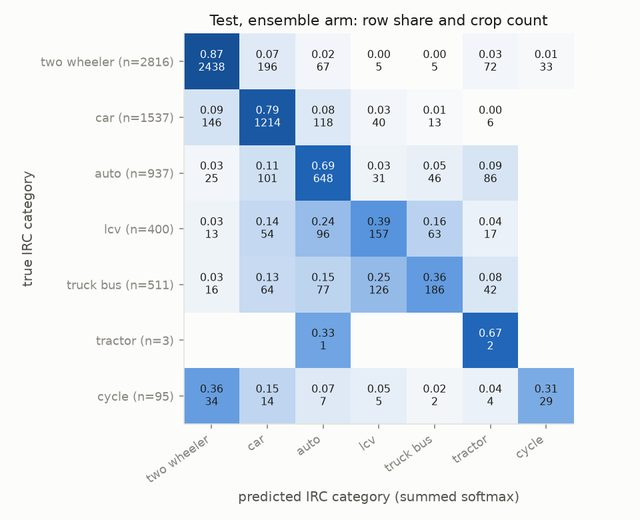

In [13]:
from src.report_figures import confusion_irc

if not SMOKE:
    show(confusion_irc(cfg), width=640)

## 6. Confidence against correctness

The score is CLIP's softmax value (14-class) or the summed softmax of the predicted IRC category. It is a
ranking signal, not a probability, so it is checked against correctness directly: reliability diagrams
(15 equal-width bins; ECE also with equal-mass bins), and coverage curves (accuracy of the crops kept as the
threshold rises). Test is drawn thick, val thin.

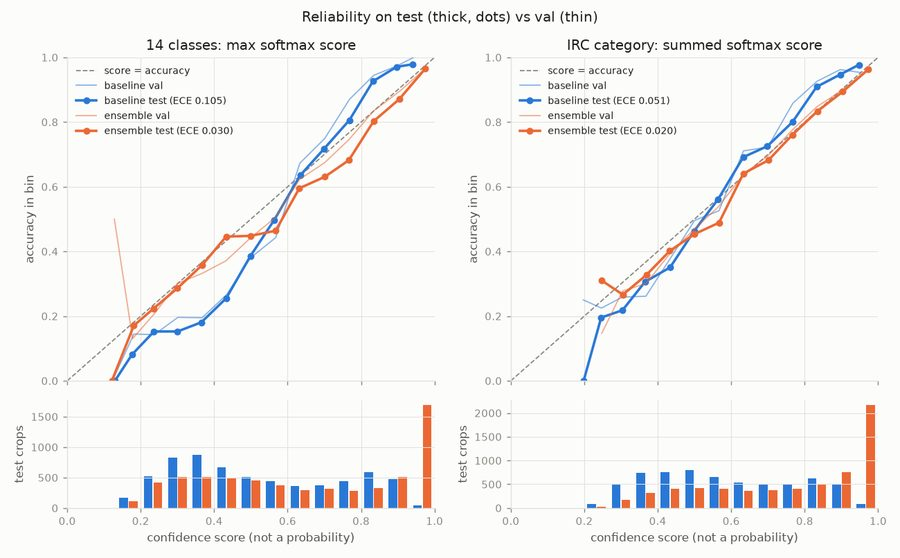

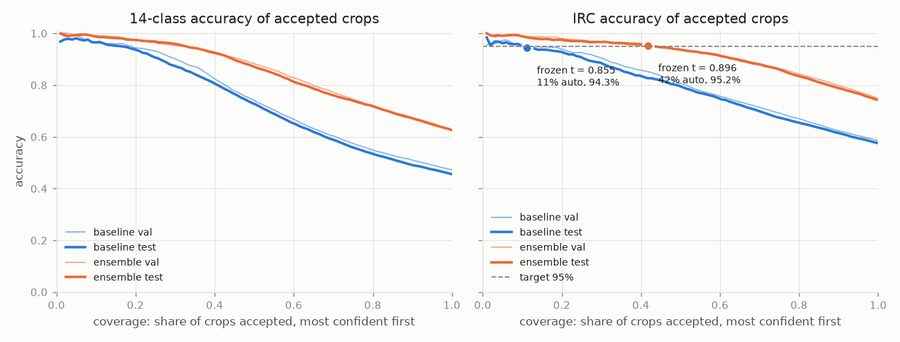

In [14]:
for f in test["figures"]:
    show(f)

In [15]:
rows = {}
for arm, a in test["arms"].items():
    r = a["rule"]
    rows[arm] = {"threshold t (from val)": r["threshold"], "coverage (accepted unseen)": r["coverage"],
                 "accepted IRC accuracy": r["accepted_irc_accuracy"], "accepted 14-class accuracy": r["accepted_class_accuracy"],
                 "share sent to review": r["human_workload"], "PCU MAE, no review": r["pcu_no_review"]["pcu_mae"],
                 "PCU MAE after review": r["pcu_after_review"]["pcu_mae"]}
print(f"review rule on {test['split']} (target 95% IRC accuracy on accepted crops, threshold frozen on val):")
pd.DataFrame(rows).round(4)

review rule on test (target 95% IRC accuracy on accepted crops, threshold frozen on val):


,baseline,ensemble
threshold t (from val),0.8546,0.8956
coverage (accepted unseen),0.1116,0.4185
accepted IRC accuracy,0.9431,0.9522
accepted 14-class accuracy,0.9189,0.8361
share sent to review,0.8884,0.5815
"PCU MAE, no review",4.7678,1.9763
PCU MAE after review,0.0795,0.2370


## 7. Failure analysis

Failures are drawn at random with the project seed from the headline arm's test errors: 30 from all
14-class errors, then 10 from the errors the review rule lets through (IRC score ≥ *t*, IRC category
wrong). None is picked by hand. I tagged the cause of each of the 40 by looking at the crop and its frame
(`analysis/failure_tags.csv`); the code's suggested cause was only a starting hint and is kept in a separate
column. The pattern is then checked on **all** test crops using tags the manifest already holds
(overlap with another box, frame edge, size).

In [16]:
from src.failures import run_failures

fail, tables, picks = run_failures(cfg)
if not SMOKE:
    tags = pd.read_csv(ROOT / "analysis" / "failure_tags.csv")
    print(tags.groupby("set")["cause"].value_counts().unstack(fill_value=0))
    fills = tags[tags["set"] == "random"]["cause"].isin(["occlusion", "context", "truncated", "small"]).sum()
    print(f"\nrandom 30: occlusion + neighbour context + frame-edge cut + small size = {fills} of 30")

failure_tags.csv already has Yash's tags: kept unchanged (same draw)
cause      context  ir_night  label  lookalike  occlusion  other  small  truncated
set                                                                               
confident        2         0      5          0          1      0      1          1
random           4         2      2          5          7      1      6          3

random 30: occlusion + neighbour context + frame-edge cut + small size = 20 of 30


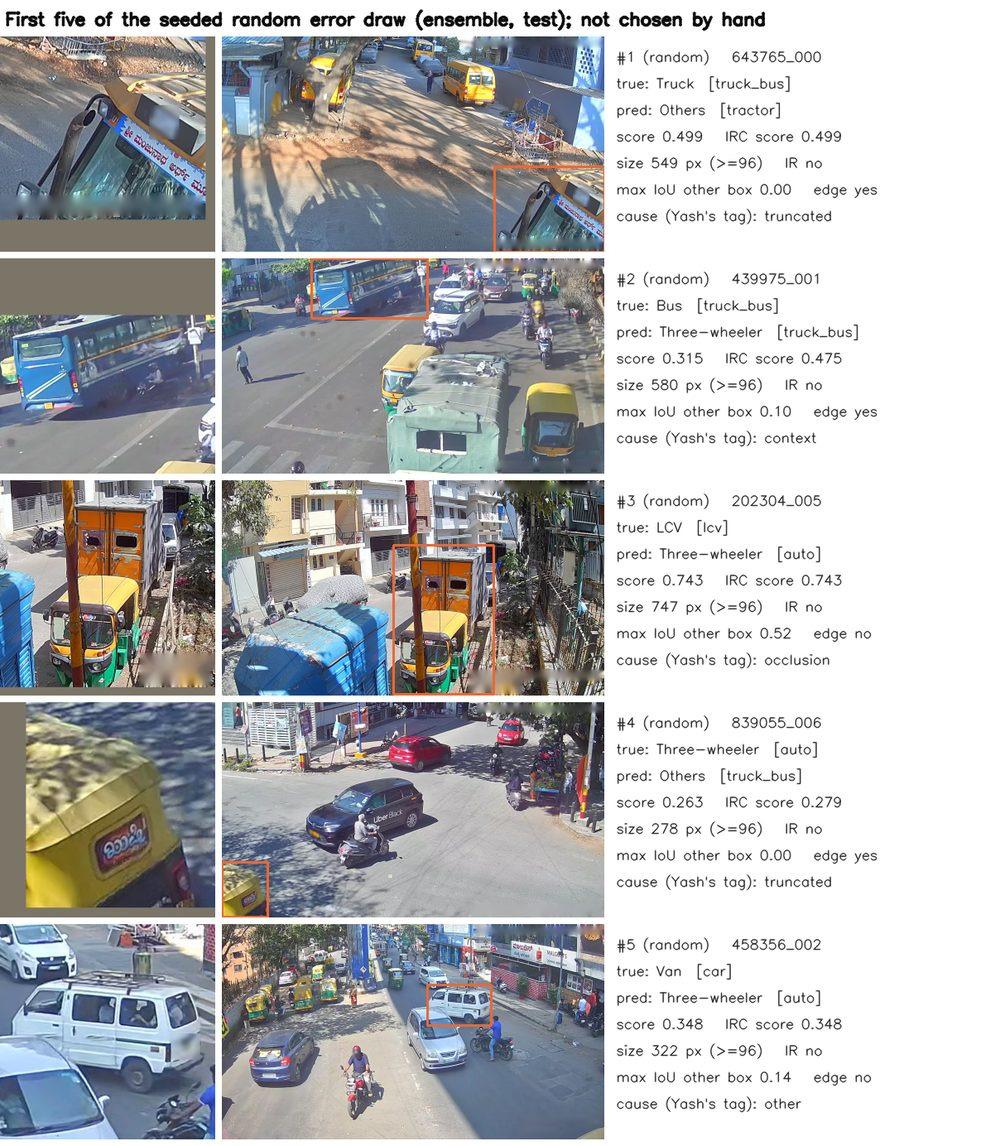

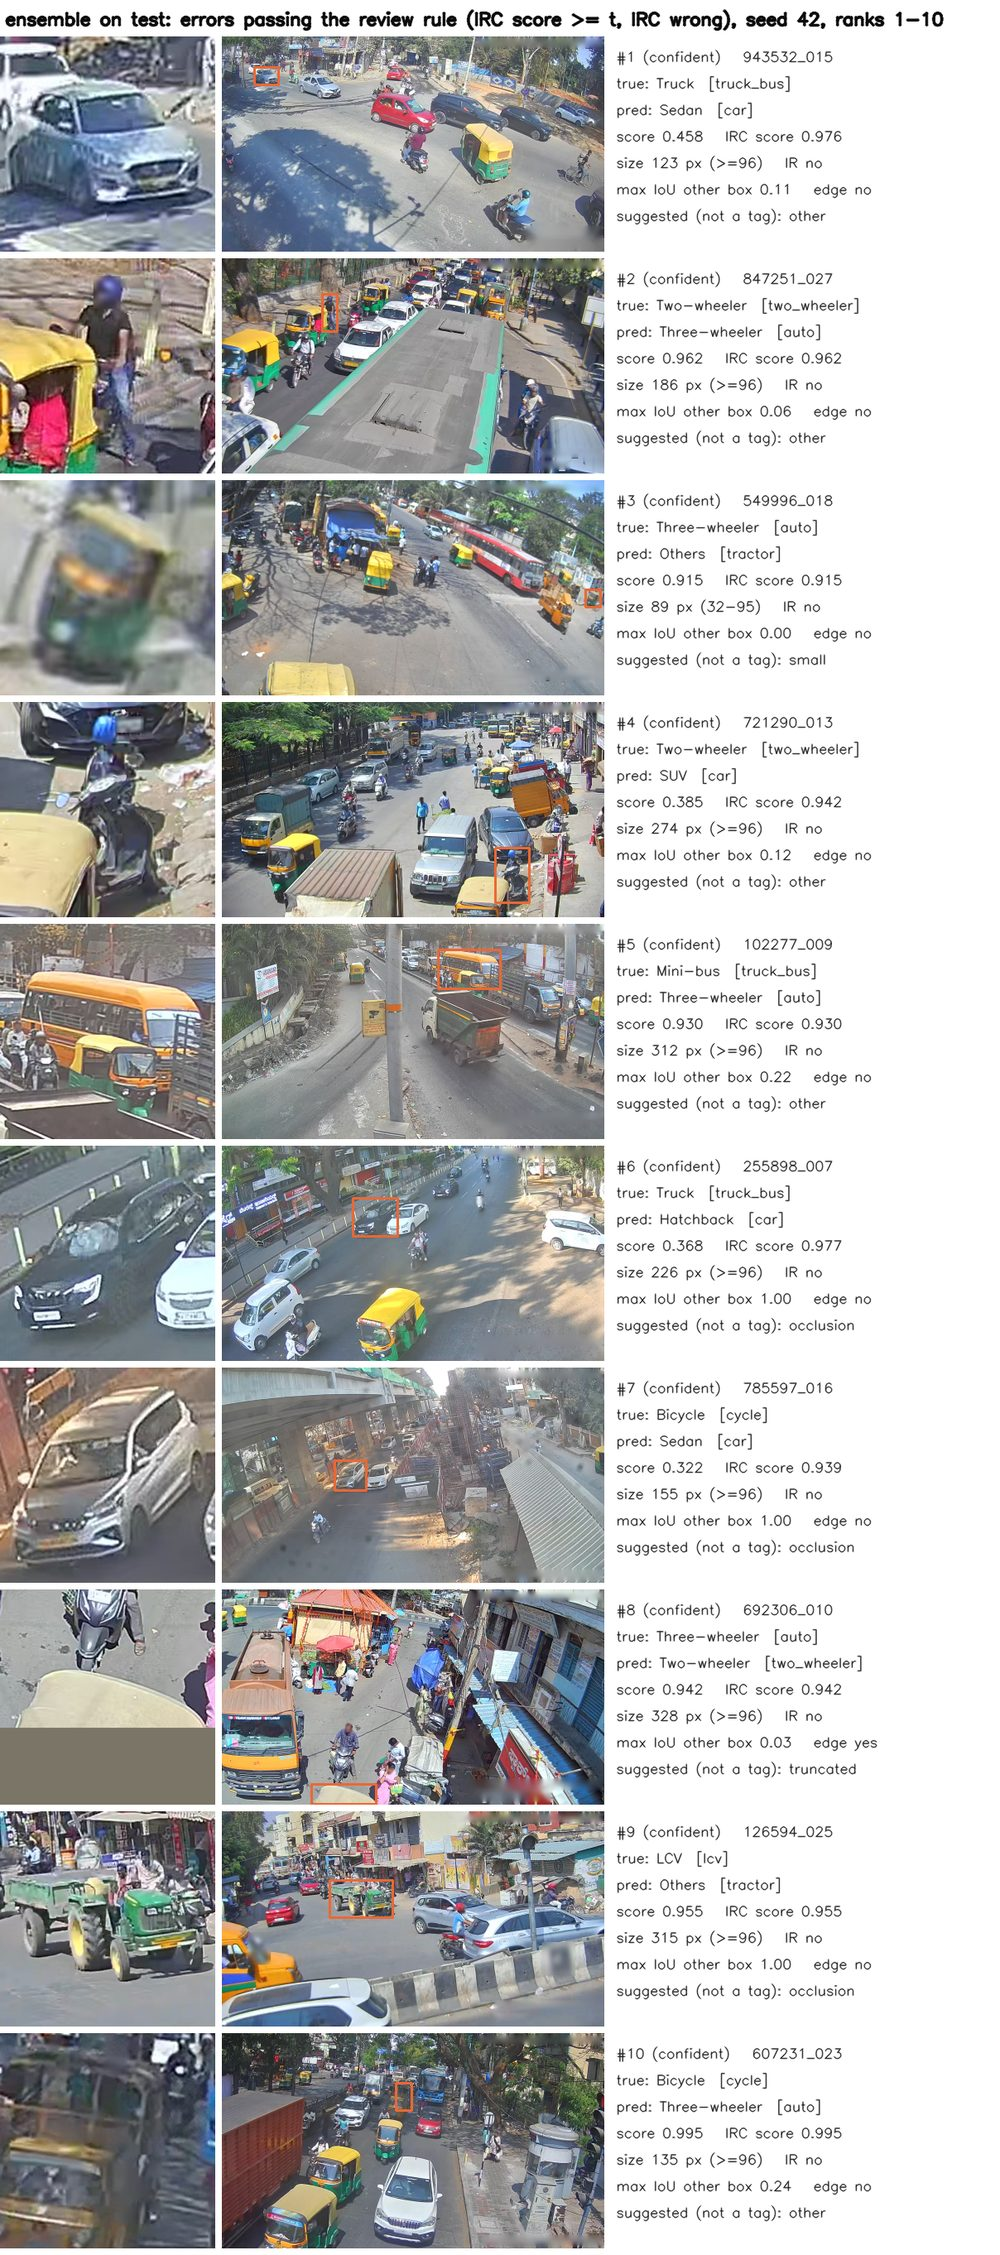

In [17]:
if not SMOKE:
    from src.report_figures import first_five_failures
    show(first_five_failures(cfg), width=1000)
    show("results/failures/confident_sheet_1.png", width=1000)

In [18]:
for name in ("occlusion_iou", "frame_edge", "size_bin", "ir", "true_class"):
    if name in tables:
        t = tables[name]
        print(f"IRC error rate over all {test['split']} crops by {name}:")
        display(t[[c for c in ("crops", "irc_errors", "irc_error_rate", "class_error_rate") if c in t]])

IRC error rate over all test crops by occlusion_iou:


,crops,irc_errors,irc_error_rate,class_error_rate
occlusion_bin,,,,
0,1686,373,0.2212,0.3025
"(0, 0.1)",2067,515,0.2492,0.3522
"[0.1, 0.3)",1627,444,0.2729,0.3614
>=0.3,919,293,0.3188,0.5767


IRC error rate over all test crops by frame_edge:


,crops,irc_errors,irc_error_rate,class_error_rate
at_frame_edge,,,,
inside frame,5286,1258,0.2380,0.3502
touches edge,1013,367,0.3623,0.4985


IRC error rate over all test crops by size_bin:


,crops,irc_errors,irc_error_rate,class_error_rate
size_bin,,,,
<32,7,5,0.7143,0.5714
32-95,1496,478,0.3195,0.3864
>=96,4796,1142,0.2381,0.3699


IRC error rate over all test crops by ir:


,crops,irc_errors,irc_error_rate,class_error_rate
ir_frame,,,,
colour,6242,1599,0.2562,0.3723
IR / greyscale,57,26,0.4561,0.5614


IRC error rate over all test crops by true_class:


,crops,irc_errors,irc_error_rate,class_error_rate
class,,,,
Hatchback,607,113,0.1862,0.6343
Sedan,356,71,0.1994,0.7247
SUV,300,54,0.1800,0.6700
MUV,212,64,0.3019,0.9198
Bus,147,50,0.3401,0.6871
Truck,339,265,0.7817,0.8260
Three-wheeler,937,289,0.3084,0.2796
Two-wheeler,2816,378,0.1342,0.1087
LCV,372,220,0.5914,0.5914


**Label check (secondary, defined after test was opened).** Some vehicles carry two ST boxes with
different classes at IoU ≥ 0.99. This changes no headline number; it shows how much of the measured error
is label noise. Assignment 1's labels carry the same duplicates.

In [19]:
from src.label_check import run_label_check

if not SMOKE:
    lc = run_label_check(cfg)
    print({s: {k: v for k, v in d.items() if k != "group_size_distribution"} for s, d in lc["splits"].items()})
    display(pd.DataFrame({arm: {"accuracy, all crops": r["all_crops_headline"]["accuracy"],
                                "accuracy, duplicates excluded": r["a_excluding_duplicate_groups"]["accuracy"],
                                "accuracy, any label counts": r["b_lenient_all_crops"]["accuracy"],
                                "IRC accuracy, all crops": r["all_crops_headline"]["irc_accuracy"],
                                "IRC accuracy, duplicates excluded": r["a_excluding_duplicate_groups"]["irc_accuracy"],
                                "accepted IRC accuracy, all crops": r["all_crops_headline"]["accepted_irc_accuracy"],
                                "accepted IRC accuracy, duplicates excluded": r["a_excluding_duplicate_groups"]["rule"]["accepted_irc_accuracy"]}
                          for arm, r in lc["test"].items()}).round(3))

{'val': {'crops': 6630, 'crops_in_groups': 679, 'share': 0.1024, 'groups': 334, 'images_with_groups': 207}, 'test': {'crops': 6299, 'crops_in_groups': 568, 'share': 0.0902, 'groups': 279, 'images_with_groups': 192}}


,baseline,ensemble
"accuracy, all crops",0.455,0.626
"accuracy, duplicates excluded",0.490,0.665
"accuracy, any label counts",0.465,0.648
"IRC accuracy, all crops",0.575,0.742
"IRC accuracy, duplicates excluded",0.585,0.753
"accepted IRC accuracy, all crops",0.943,0.952
"accepted IRC accuracy, duplicates excluded",0.948,0.959


## 8. Ethics and privacy

**Risk.** CLIP matches images against any text. The same pipeline pointed at traffic cameras could be
asked for people ("a woman in a red saree riding a scooter") instead of vehicle classes, turning a
counting tool into a tool for finding individuals. Frames also show faces and number plates.

**Mitigations implemented.**
1. Closed vocabulary: the classifier is built only from prompt files registered by sha256; free text is
   refused (demonstrated below).
2. Image embeddings stay in memory in this run; no embedding array is written to disk (checked below). The
   outputs are per-crop class and score and per-frame counts only.
3. Every figure that shows pixels passes through a face blur (OpenCV Haar cascade) plus manual boxes, and I
   checked each report figure by eye (`results/redaction_checklist.csv`).

In [20]:
from src.privacy import assert_no_embedding_files, closed_vocabulary_demo

print(closed_vocabulary_demo(cfg, model, processor))
n = assert_no_embedding_files(ROOT / "results", ROOT / "report", ROOT / "analysis", ROOT / "prompts", RES)
print(f"no embedding arrays among {n} files in results/, report/, analysis/, prompts/")
cache = cfg["paths"]["cache_dir"]
new = [p for p in cache.rglob("*") if p.is_file() and p.stat().st_mtime >= RUN_STARTED] if cache.exists() else []
assert not new, f"this run wrote to the cache: {new}"
print("nothing was written to the embedding cache during this run")

refused: free_text.yaml (sha256 50c3c59eecec) is not a frozen prompt file; classifiers are built only from frozen prompt YAMLs
no embedding arrays among 141 files in results/, report/, analysis/, prompts/
nothing was written to the embedding cache during this run


In [21]:
if not SMOKE:
    from src.report_figures import redaction_checklist
    display(redaction_checklist(cfg, ["report/figures/failures_first5.png"]))

,file,in_report,shows_pixels,faces_still_detected_after_redaction,checked_by_yash,plates_or_faces_to_add_to_redact_csv
0,report/figures/failures_first5.png,True,True,0,"2026-11-11: checked, nothing to redact",none
1,report/figures/leak_pair_01.jpg,True,True,0,,
2,report/figures/leak_pair_12.jpg,True,True,2,,
3,results/figures/val_examples.png,True,True,1,2026-11-11: Claude checked by eye at Yash's re...,none
4,results/failures/confident_sheet_1.png,False,True,0,"2026-11-11: checked, nothing to redact",none
5,results/failures/random_sheet_1.png,False,True,1,2026-11-11: Claude checked by eye at Yash's re...,none
6,results/failures/random_sheet_2.png,False,True,2,2026-11-11: Claude checked by eye at Yash's re...,none
7,results/failures/random_sheet_3.png,False,True,1,2026-11-11: Claude checked by eye at Yash's re...,none
8,results/leak_test_val/sheet_1.jpg,False,True,3,2026-11-11: Claude checked by eye at Yash's re...,none
9,results/leak_test_val/sheet_2.jpg,False,True,4,2026-11-11: Claude checked by eye at Yash's re...,none


## Numbers for the report

Every number the report quotes is collected from `results/` into `report/numbers.json`.

In [22]:
if not SMOKE:
    sys.path.insert(0, str(ROOT / "report"))
    import extract_outputs
    extract_outputs.main()
print(f"run time: {(time.time() - RUN_STARTED) / 60:.1f} min")

wrote /Users/yashrenwa/Personal/Projects/uvh26-clip-zeroshot/report/numbers.json (553 numbers)
run time: 6.8 min
